# SwarmBench: run a benchmark mode

This notebook runs one of the three benchmark modes with a list of agents and a number of seeds, then shows the
metrics, social welfare and the milliseconds each agent needs per decision.

| Mode | Market | What it answers |
|---|---|---|
| `solo` | each entry alone against the three supplied bots (4 nodes) | the original challenge |
| `head-to-head` | every unordered pair of entries (2 nodes) | who beats whom |
| `all-together` | every entry in one market | how the strategies fare as a population |

The same run from a shell is `swarmbench --mode <mode> --agents <...> --seeds <n>`.
Install with `pip install "swarmbench[notebooks]"` (Jupyter and matplotlib).

In [1]:
import json
from pathlib import Path
import tempfile

from IPython.display import Image, Markdown, display

import swarmbench as sb
from swarmbench.report import figure, markdown, summarize

print("SwarmBench", sb.__version__)

SwarmBench 1.0.0


## The catalog

Agents are ordered from the simplest idea to the most complex: traditional rules, one-round optimization,
planning with the exact bot model, planning with an identified market, and machine learning.
**Realistic** means the agent never uses the supplied bots' names or code, so it can face unnamed opponents.

In [2]:
rows = ["| # | key | family | realistic | name |", "|---:|---|---|---|---|"]
for i, spec in enumerate(sb.resolve(["paper"]), start=1):
    rows.append(f"| {i} | `{spec.key}` | {spec.family} | {'yes' if spec.realistic else 'no'} | {spec.name} |")
display(Markdown("\n".join(rows)))

| # | key | family | realistic | name |
|---:|---|---|---|---|
| 1 | `naive-max` | Traditional (rules) | yes | Naive max (bot) |
| 2 | `even-split` | Traditional (rules) | yes | Even split (bot) |
| 3 | `proportional` | Traditional (rules) | yes | Proportional (bot) |
| 4 | `template` | Traditional (rules) | yes | Template: weight bids |
| 5 | `taper` | Traditional (rules) | yes | Battery taper |
| 6 | `floors` | Optimization (one round) | yes | Floor reservation |
| 7 | `price-taker` | Optimization (one round) | yes | Price-taker split + floors |
| 8 | `market-taper` | Optimization (one round) | yes | Price-taker + taper |
| 9 | `kelly` | Optimization (one round) | yes | Guarded Kelly best response |
| 10 | `kelly-drain` | Optimization (one round) | yes | Kelly with drain price |
| 11 | `kelly-blend` | Optimization (one round) | yes | Taper/Kelly blend |
| 12 | `bot-aware` | Optimization (one round) | no | Best response to bot forecasts |
| 13 | `lookahead` | Planning (exact bot model) | no | Lookahead planner (MPC) |
| 14 | `lookahead-cutoff` | Planning (exact bot model) | no | Lookahead + cutoff crossings |
| 15 | `lookahead-refine` | Planning (exact bot model) | no | Lookahead + refinement |
| 16 | `cycle-aware` | Planning (exact bot model) | no | Cycle-Aware planner (selected) |
| 17 | `physics` | Planning (exact bot model) | no | + online battery physics |
| 18 | `residual` | Planning (exact bot model) | no | + market residual |
| 19 | `noisy-scenarios` | Planning (exact bot model) | no | + noisy scenarios |
| 20 | `prob-cutoff` | Planning (exact bot model) | no | + probabilistic cutoffs |
| 21 | `cvar` | Planning (exact bot model) | no | + CVaR risk |
| 22 | `dynamic-horizon` | Planning (exact bot model) | no | + dynamic horizon |
| 23 | `modes` | Planning (exact bot model) | no | + strategy modes |
| 24 | `adaptive-cycle-aware` | Planning (exact bot model) | no | Adaptive cycle-aware |
| 25 | `identified-linear` | Planning (identified market) | yes | Identified market: linear |
| 26 | `identified-logit` | Planning (identified market) | yes | Identified market: logit demand |
| 27 | `identified-structural` | Planning (identified market) | yes | Identified market: rational demand |
| 28 | `identified-robust` | Planning (identified market) | yes | Identified market: robust crossings |
| 29 | `ucb-energy` | Machine learning | yes | UCB over energy prices |
| 30 | `ridge-value` | Machine learning | no | Learned value (ridge), greedy |
| 31 | `ridge-terminal-4` | Machine learning | no | Planner + ridge terminal (4 rounds) |
| 32 | `ridge-terminal-6` | Machine learning | no | Planner + ridge terminal (6 rounds) |
| 33 | `catboost-terminal` | Machine learning | no | Planner + CatBoost terminal |
| 34 | `linucb-modes` | Machine learning | no | LinUCB mode selector |
| 35 | `archetype-learning` | Machine learning | no | Bayesian rival archetypes |
| 36 | `learned-shortlist` | Machine learning | no | Learned candidate shortlist |

## Parameters

`AGENTS` takes catalog keys or the groups `paper` (all 36 entries), `agents`, `bots`, `realistic` and `distinct`.
Planning agents take about a second per 60-round episode, so start small.

In [3]:
MODE = "solo"                 # "solo", "head-to-head" or "all-together"
AGENTS = ["template", "kelly", "identified-robust", "cycle-aware"]
SEEDS = 3
SEED_START = 70001            # the stored experiments use seeds 70001-70100
WORKERS = 2

## Run

In [4]:
rows = sb.run_mode(MODE, AGENTS, range(SEED_START, SEED_START + SEEDS), workers=WORKERS)
summary = summarize(rows, MODE)
spec = {"mode": MODE, "agents": AGENTS, "seeds": SEEDS, "seed_start": SEED_START, "workers": WORKERS}
print(len(rows), "participant rows")

12 participant rows


## Results

The full table: score with a 95% interval, ranks, social welfare, log social welfare and ms per decision.

In [5]:
display(Markdown(markdown(summary, spec, MODE, None)))

# Solo: each entry against the three supplied bots

Seeds 70001–70003 (3), `graded` scenario, 60 rounds, unchanged arena engine in-process. Every participant has the same device (minted from the seed and a fixed device label). Agents are listed in idea order: traditional rules, optimization, model-based planning, machine learning. **Realistic** = never uses the bots' names or code, so it can face unnamed opponents.

| # | Agent | Family | Realistic | Mean score | ±95% | Score rank | Δ vs cycle-aware (paired) | W/L vs cycle-aware | Beat all bots | Mean rank (of 4) | Idle | Floors | Exceptions | ms mean | ms max | Log social welfare | Bots' score | Welfare (Σ scores) |
|---:|---|---|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 1 | Template: weight bids (`template`) | Traditional (rules) | yes | 13.258 | 1.268 | 4 | -30.22% ±5.86 | 0/3 | 0/3 | 2.33 | 19.0 | 4.67 | 0 | 0.962 | 21.7 | -188.1 | 44.46 | 57.72 |
| 2 | Guarded Kelly best response (`kelly`) | Optimization (one round) | yes | 16.541 | 2.017 | 3 | -13.08% ±7.22 | 0/3 | 3/3 | 1.00 | 4.0 | 2.67 | 0 | 2.8 | 6.3 | -211.8 | 37.39 | 53.93 |
| 3 | Cycle-Aware planner (selected) (`cycle-aware`) | Planning (exact bot model) | no | 19.029 | 1.736 | 1 | reference | — | 3/3 | 1.00 | 11.0 | 0.67 | 0 | 130 | 341 | -209.9 | 36.89 | 55.92 |
| 4 | Identified market: robust crossings (`identified-robust`) | Planning (identified market) | yes | 18.580 | 2.372 | 2 | -2.15% ±13.00 | 1/2 | 3/3 | 1.00 | 9.3 | 2.33 | 0 | 101 | 245 | -206.0 | 37.06 | 55.64 |

Log social welfare is the arena's Σ_i log u_i summed over rounds for the 4-node market; welfare is the sum of all four final scores. Δ is the mean per-seed relative gain with a normal 95% interval; W/L counts seeds with a strictly higher/lower score.

Times are wall-clock milliseconds per decision measured inside the run (2 parallel workers), so they include contention; they are comparable across agents, not portable.


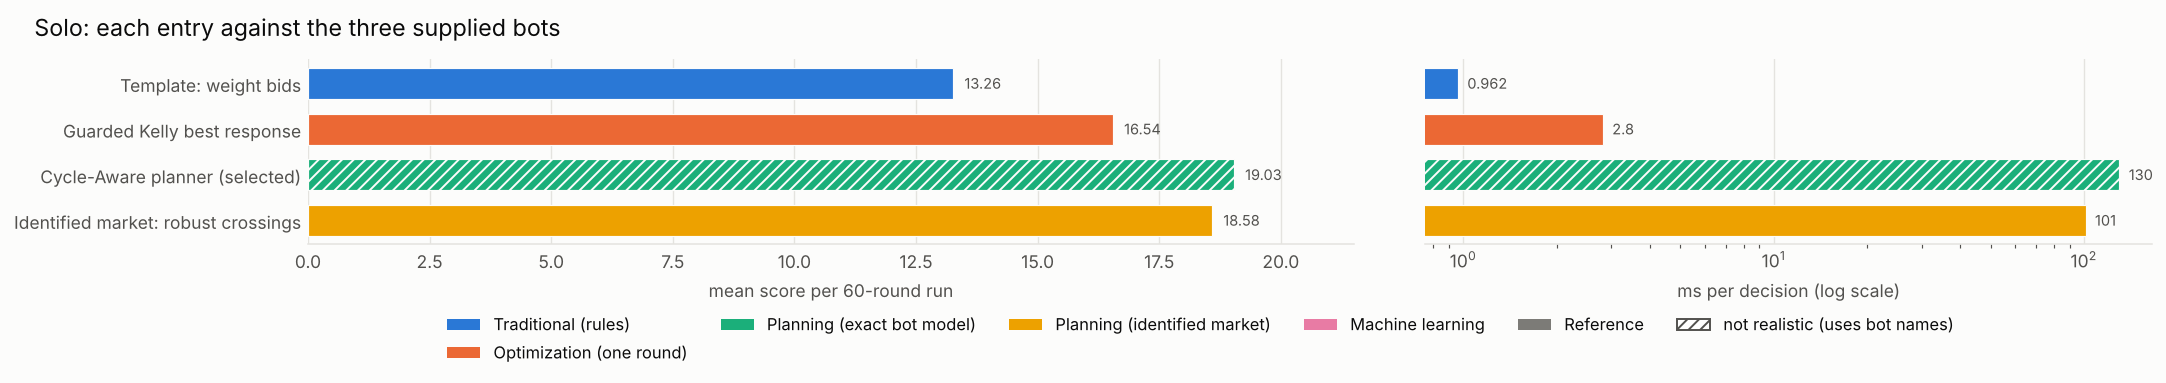

In [6]:
path = Path(tempfile.mkdtemp()) / "figure.png"
if figure(summary, MODE, path):          # needs matplotlib (the report or notebooks extra)
    display(Image(str(path)))

## Try the other modes

Change `MODE` above, or run a head-to-head between two realistic agents and two bots:

In [7]:
h2h = sb.run_mode("head-to-head", ["identified-robust", "kelly", "naive-max", "proportional"],
                  range(SEED_START, SEED_START + 2), workers=WORKERS)
s = summarize(h2h, "head-to-head")
for key, row in s["_matrix"].items():
    print(f"{key:20}", {k: round(v, 2) for k, v in row.items()})

identified-robust    {'kelly': 1.0, 'naive-max': 1.0, 'proportional': 1.0}
kelly                {'identified-robust': 0.0, 'naive-max': 0.0, 'proportional': 1.0}
naive-max            {'identified-robust': 0.0, 'kelly': 1.0, 'proportional': 0.5}
proportional         {'identified-robust': 0.0, 'kelly': 0.0, 'naive-max': 0.5}


## The stored results (100 seeds)

A clone of the repository holds every experiment in `results/paper` (see *Reproducing the results* in the
documentation). This cell reads their summaries without re-running anything.

In [8]:
RESULTS = next((p for p in (Path("results/paper"), Path("../results/paper")) if p.is_dir()), None)
if RESULTS is None:
    print("results/paper not found: run this notebook from a clone of the repository")
else:
    for mode in sb.MODES:
        stored = json.loads((RESULTS / mode / "summary.json").read_text())
        metric = "win_rate" if mode == "head-to-head" else "mean_score"
        best = sorted((k for k in stored if not k.startswith("_")), key=lambda k: -stored[k][metric])[:5]
        print(f"{mode:13} top 5 by {metric}:", ", ".join(f"{k} {stored[k][metric]:.3f}" for k in best))

solo          top 5 by mean_score: modes 19.130, dynamic-horizon 19.122, cvar 19.101, prob-cutoff 19.063, noisy-scenarios 19.056
head-to-head  top 5 by win_rate: learned-shortlist 0.867, archetype-learning 0.823, kelly-drain 0.823, ucb-energy 0.810, identified-linear 0.796
all-together  top 5 by mean_score: naive-max 0.532, template 0.532, even-split 0.529, proportional 0.528, taper 0.413
